# 포켓몬 타입별 기본 능력치 — 웹 스크래핑 × 탐색적 데이터 분석(EDA)
**AIFFEL D010 웹 스크래핑 실습 · 2026-10-29**  
원본: https://pokemondb.net/pokedex/all  

**검증·출처 구분**: `USE_LIVE=True`일 때 `requests`로 실제 웹페이지를 요청합니다. 접속이 차단되면 **교육용 재구성 HTML 표본 70행**을 사용하며, 실행 로그와 결과 파일에 반드시 `OFFLINE_FIXTURE`로 기록됩니다. 오프라인 재구성 HTML은 원본 사이트의 HTML 캡처가 아닙니다. **인터넷이 연결되지 않았을 때 라이브 스크래핑이 성공했다고 주장하지 마세요.**

8단계: ①요청 → ②정적·동적 판단 → ③HTML 구조 확인 → ④BeautifulSoup 추출 → ⑤pandas 정제 → ⑥검증 → ⑦윤리 → ⑧EDA·시각화·보고. 다만 실제 자동 수집 실행에서는 ⑦을 ①보다 먼저 확인해야 합니다.

## 준비 — 라이브러리 및 분석 질문
**왜 이 라이브러리를 선택했나?** `requests`: HTTP / `BeautifulSoup`: 정적 HTML 요소 추출 / `pandas`: 정제·집계 / `matplotlib`: 시각화 / `logging`: 과정 증거 저장.

**분석 질문**: Q1 타입 분포? Q2 1차 타입별 평균 능력치? Q3 공격과 스피드의 관계? Q4 능력치 총합 상위 종은?  
**분석 단위**: 동일 전국도감 번호의 여러 폼을 제거한 **기본형 한 행**. 타입별 비교는 **1차 타입만** 사용하며, 복합 타입·진화 단계·전설 여부 등이 결과에 영향을 줍니다.

In [1]:
from pathlib import Path
import requests, pandas as pd, numpy as np
from bs4 import BeautifulSoup
from datetime import datetime
from urllib.robotparser import RobotFileParser
import logging, time, matplotlib.pyplot as plt
from matplotlib import font_manager

ROOT=Path.cwd(); OUT=ROOT/'output'; OUT.mkdir(exist_ok=True)
URL='https://pokemondb.net/pokedex/all'
USE_LIVE=False  # 사이트 접속 가능 시 실시간 웹 스크래핑
STATS=['hp','attack','defense','sp_attack','sp_defense','speed']
logger=logging.getLogger('pokemon_eda')
logger.handlers.clear(); logger.setLevel(logging.INFO)
h=logging.FileHandler(OUT/'process_log.txt',encoding='utf-8',mode='w')
h.setFormatter(logging.Formatter('%(asctime)s | %(levelname)s | %(message)s'))
logger.addHandler(h)
logger.info('START source=%s',URL)
print('분석 질문: 타입별 분포 / 평균 능력치 / 공격-스피드 / 상위 포켓몬')

분석 질문: 타입별 분포 / 평균 능력치 / 공격-스피드 / 상위 포켓몬


## 1단계 · HTTP 요청 — requests.get
`requests.get(URL, timeout=15)`는 웹 서버에 **GET 요청**을 보내고 응답을 받습니다. `raise_for_status()`는 4xx/5xx 오류를 잡습니다. `response.text`에는 HTML이 담깁니다. 라이브 접근 실패 시 교육용 재구성 HTML로 전환하며 경고를 남깁니다.

In [2]:
mode='OFFLINE_FIXTURE'
source_html=None
if USE_LIVE:
    try:
        # 0. 사이트의 공개 robots.txt 정책부터 먼저 확인합니다.
        robots_url='https://pokemondb.net/robots.txt'
        robots_response=requests.get(robots_url,timeout=10)
        robots_response.raise_for_status()
        rp=RobotFileParser()
        rp.parse(robots_response.text.splitlines())
        ua='EducationalDataAnalysis/1.0'
        if not rp.can_fetch(ua,URL):
            raise RuntimeError('robots.txt policy prevents access to this URL')
        delay=rp.crawl_delay(ua)
        logger.info('ROBOTS CHECK permitted=True crawl_delay=%r',delay)
        if delay: time.sleep(delay)
        # 1. 페이지 HTML은 한 번만 요청합니다.
        response=requests.get(URL,headers={'User-Agent':'Mozilla/5.0 (compatible; EducationalDataAnalysis/1.0)'}, timeout=15)
        print('HTTP 상태:',response.status_code)
        response.raise_for_status()
        source_html=response.text
        mode='LIVE'
        logger.info('HTTP SUCCESS status=%s bytes=%s',response.status_code,len(response.content))
    except (requests.RequestException,RuntimeError) as ex:
        logger.warning('LIVE FAILED: %r',ex)
        print('라이브 접속/허용 확인 실패 — 교육용 표본으로 대체합니다:',type(ex).__name__)
if source_html is None:
    fixture_path=ROOT/'educational_fixture_70.html'
    if not fixture_path.exists():
        raise FileNotFoundError('교육용 HTML이 없습니다. ZIP 전체를 같은 폴더에 압축 해제하세요.')
    source_html=fixture_path.read_text(encoding='utf-8')
    logger.warning('OFFLINE_FIXTURE: verified 70 row subset, NOT actual HTML snapshot or live scrape')
print('자료 출처 상태:',mode)

자료 출처 상태: OFFLINE_FIXTURE


## 2단계 · 정적·동적 페이지 판별
원본 페이지의 HTML에 `table#pokedex`가 들어 있는지 확인합니다. 있으면 BeautifulSoup으로 정적 HTML 표를 추출할 수 있습니다. 없으면 동적 렌더링/사이트 변경/차단 등의 가능성을 점검해야 합니다.

In [3]:
soup=BeautifulSoup(source_html,'html.parser')
table=soup.select_one('table#pokedex')
if table is None: raise RuntimeError('table#pokedex 없음: 페이지 구조 변경 또는 차단 여부 확인')
print('HTML 표 발견:',bool(table));logger.info('SELECTOR FOUND table#pokedex')

HTML 표 발견: True


## 3단계 · HTML 요소 구조 확인
선택자: `table#pokedex` = id가 pokedex인 표, `tbody tr` = 표의 행, `td` = 행의 열, `a.type-icon` = 타입 요소. 포켓몬 DB의 표 헤더는 번호 / 이름 / 타입 / 총합 / HP / 공격 / 방어 / 특수공격 / 특수방어 / 스피드입니다.

In [4]:
trs=table.select('tbody tr')
print('HTML 행 수:',len(trs))
print('첫 행의 열 개수:',len(trs[0].select('td')) if trs else 0)
logger.info('HTML ROWS: %s',len(trs))

HTML 행 수: 70
첫 행의 열 개수: 10


## 4단계 · BeautifulSoup 추출
`for tr in trs`로 행을 한 번씩 반복합니다. `select('td')`로 열 10개를 찾고, `get_text(strip=True)`로 글자를, `select('.type-icon')`으로 타입을 꺼냅니다. `rows.append({...})`로 딕셔너리를 리스트에 축적합니다.

In [5]:
rows=[]
for tr in trs:
    tds=tr.select('td')
    if len(tds)!=10: continue
    type_items=[a.get_text(' ',strip=True) for a in tds[2].select('.type-icon')]
    if not type_items: type_items=tds[2].get_text(' ',strip=True).split()
    a=tds[1].select_one('a.ent-name')
    name=a.get_text(' ',strip=True) if a else tds[1].get_text(' ',strip=True)
    try:
        row={'national_no':int(tds[0].get_text(' ',strip=True).replace('#','')),
             'name':name,'type1':type_items[0],
             'type2':type_items[1] if len(type_items)>1 else np.nan}
        for i,k in enumerate(['total']+STATS,start=3):
            row[k]=int(tds[i].get_text(strip=True))
        rows.append(row)
    except (ValueError,IndexError) as ex:
        logger.warning('ROW PARSE FAILURE: %r',ex)
raw=pd.DataFrame(rows)
print('추출 원본 행 수:',len(raw));logger.info('RAW EXTRACTED rows=%d',len(raw))
if raw.empty: raise RuntimeError('데이터 0건 — 선택자 또는 응답 확인 필요')
raw.to_csv(OUT/'pokemon_raw.csv',index=False,encoding='utf-8-sig')
raw.head()

추출 원본 행 수: 70


,national_no,name,type1,type2,total,hp,attack,defense,sp_attack,sp_defense,speed
0,1,Bulbasaur,Grass,Poison,318,45,49,49,65,65,45
1,2,Ivysaur,Grass,Poison,405,60,62,63,80,80,60
2,3,Venusaur,Grass,Poison,525,80,82,83,100,100,80
3,4,Charmander,Fire,NaN,309,39,52,43,60,50,65
4,5,Charmeleon,Fire,NaN,405,58,64,58,80,65,80


## 5단계 · pandas 정제
`drop_duplicates('national_no')`는 동일 전국도감 번호의 여러 폼 중 첫 행을 남겨 **기본형 비교군**으로 만듭니다. `pd.to_numeric`은 숫자 자료형 변환, `isna().sum()`은 결측 개수 확인입니다. **복합 타입은 type2가 비어 있을 수 있는데 이는 정상**입니다.

In [6]:
clean=raw.sort_values('national_no',kind='stable').drop_duplicates('national_no',keep='first').copy()
for col in ['national_no','total']+STATS: clean[col]=pd.to_numeric(clean[col],errors='coerce')
clean=clean.dropna(subset=['national_no','name','type1']+STATS)
clean['national_no']=clean['national_no'].astype('int64')
clean.to_csv(OUT/'pokemon_clean.csv',index=False,encoding='utf-8-sig')
print('원본 행:',len(raw),'정제 후 기본형:',len(clean))
print('결측 수:',clean.isna().sum().to_dict())
logger.info('CLEAN rows=%d unique_id=%d',len(clean),clean.national_no.nunique())

원본 행: 70 정제 후 기본형: 70
결측 수: {'national_no': 0, 'name': 0, 'type1': 0, 'type2': 41, 'total': 0, 'hp': 0, 'attack': 0, 'defense': 0, 'sp_attack': 0, 'sp_defense': 0, 'speed': 0}


## 6단계 · 수집 결과 검증
성공 기준은 코드 실행 여부가 아니라 **데이터의 타당성**입니다. 행 수가 0보다 큰지, 번호가 고유한지, 능력치 합계가 일치하는지, 수치가 결측 없는지 검사합니다.

In [7]:
check={'nonzero_rows':len(clean)>0,
       'unique_national_no':clean.national_no.is_unique,
       'valid_stat_total':bool((clean[STATS].sum(axis=1)==clean.total).all()),
       'no_missing_numeric':bool(clean[STATS+['total']].notna().all().all())}
print('검증:',check)
assert all(check.values()),f'검증 실패: {check}'
logger.info('VALIDATION PASS: %s',check)

검증: {'nonzero_rows': True, 'unique_national_no': True, 'valid_stat_total': True, 'no_missing_numeric': True}


## 7단계 · 수집 윤리와 기록
원본 `https://pokemondb.net/robots.txt` 공개 규칙에서는 `User-agent: *` 아래 `/pokedex/all`에 대한 명시적 Disallow가 보이지 않고 `Crawl-delay: 2`가 있습니다(2026-10-29 웹 조회). 자동 수집 전 매번 재확인하고, 한 페이지 요청만 하며, 이미지·텍스트 전문을 재배포하지 않습니다. robots.txt 준수는 저작권·이용약관 검토를 대신하지 않습니다. **실제 실행에서는 이 점검을 수집 전에 선행**해야 합니다.

In [8]:
print('실습 출처:',URL)
print('자료 수집 방식:',mode)
print('로봇 규칙 확인 URL: https://pokemondb.net/robots.txt')
logger.info('ETHICS single-page one-request; site terms must be independently checked')

실습 출처: https://pokemondb.net/pokedex/all
자료 수집 방식: OFFLINE_FIXTURE
로봇 규칙 확인 URL: https://pokemondb.net/robots.txt


## 8단계 · EDA + 시각화 + 결과 자료 저장
Q1 1차 타입별 빈도; Q2 타입별 평균 6능력치 및 Total; Q3 공격/스피드 산점도; Q4 강한 개체 순위. 라이브 실행 시 결과가 표본 CSV와 다를 수 있습니다. *종족값(Base stats)은 게임 내부 기준값이지 실제 대전 승률이 아닙니다.*

데이터 모드: OFFLINE_FIXTURE | 분석 행: 70 | 1차 타입 종류: 11
           n  total
type1              
Fire       7  422.4
Water      8  408.0
Psychic    3  403.3
Fairy      2  403.0
Electric   2  402.5
Fighting   5  395.0
Grass      8  392.9
Poison    10  372.4
Ground     4  360.0
Normal    11  353.1


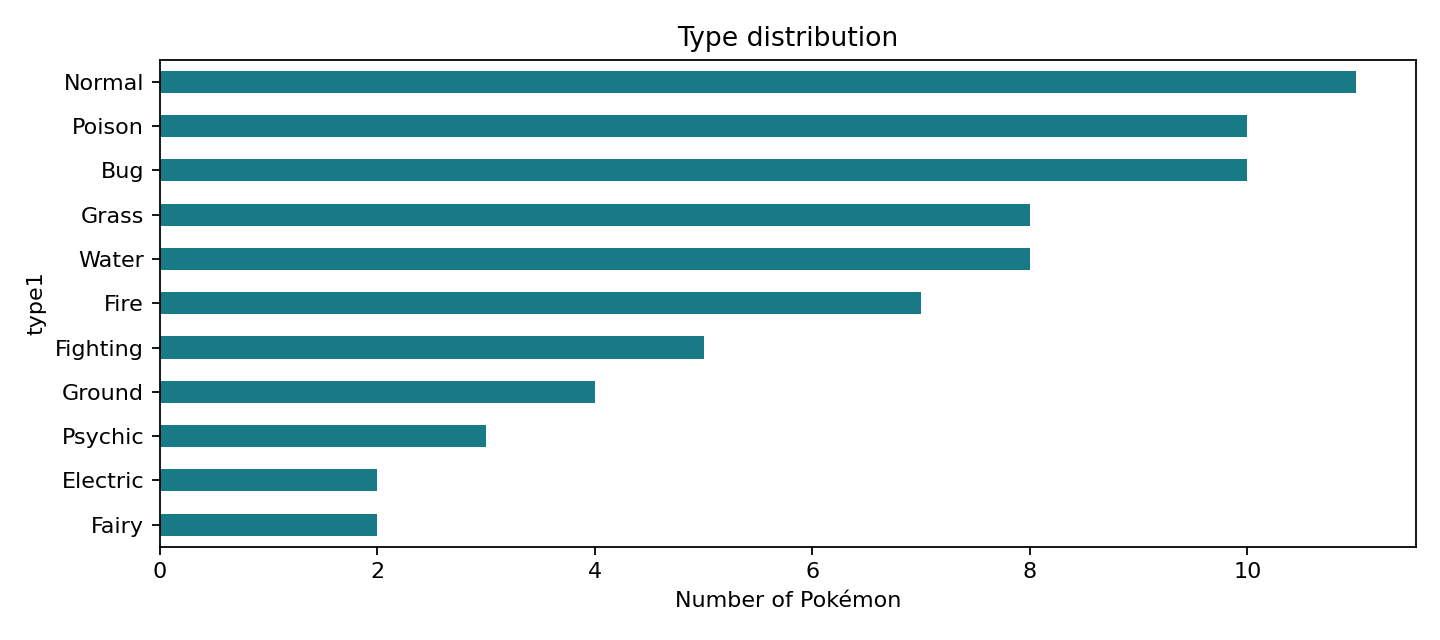

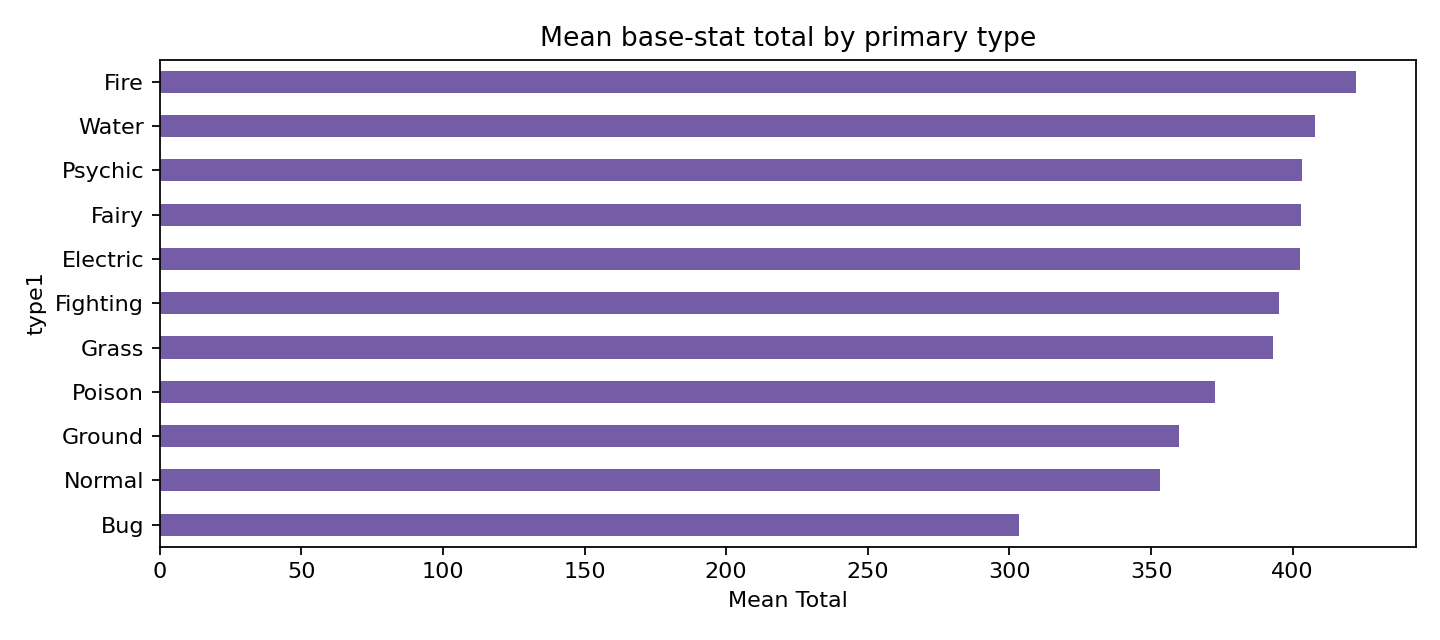

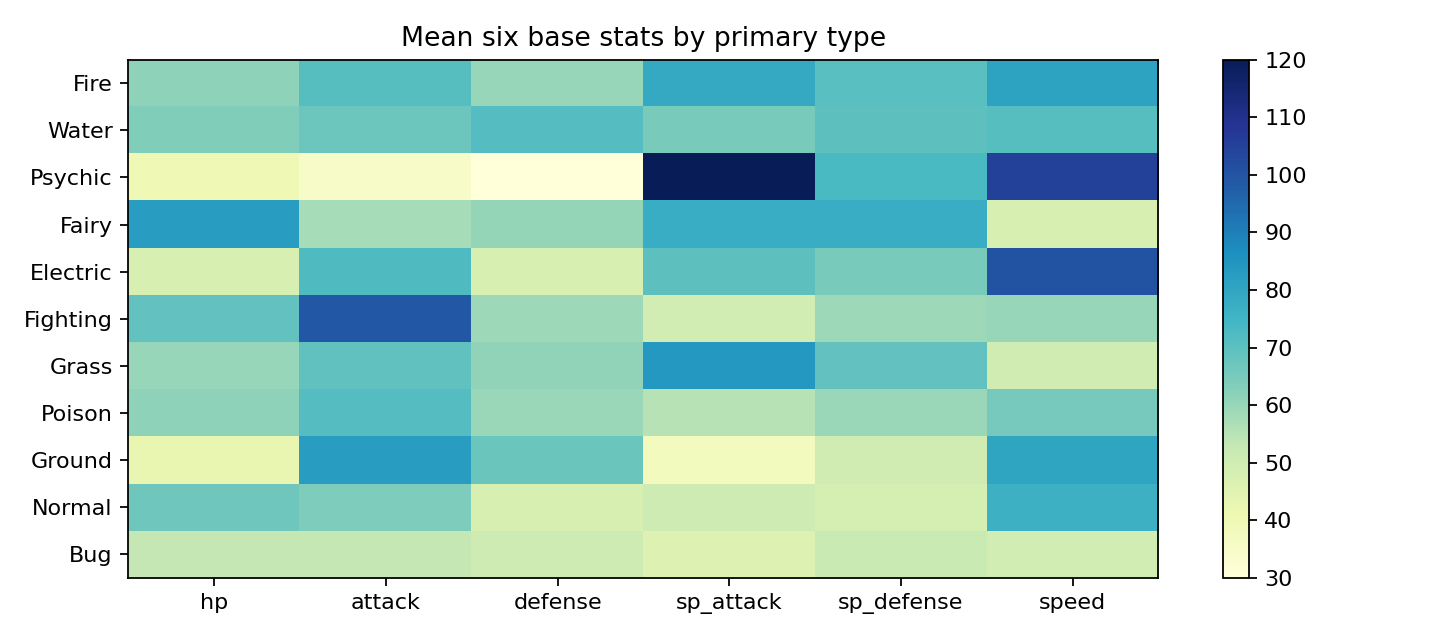

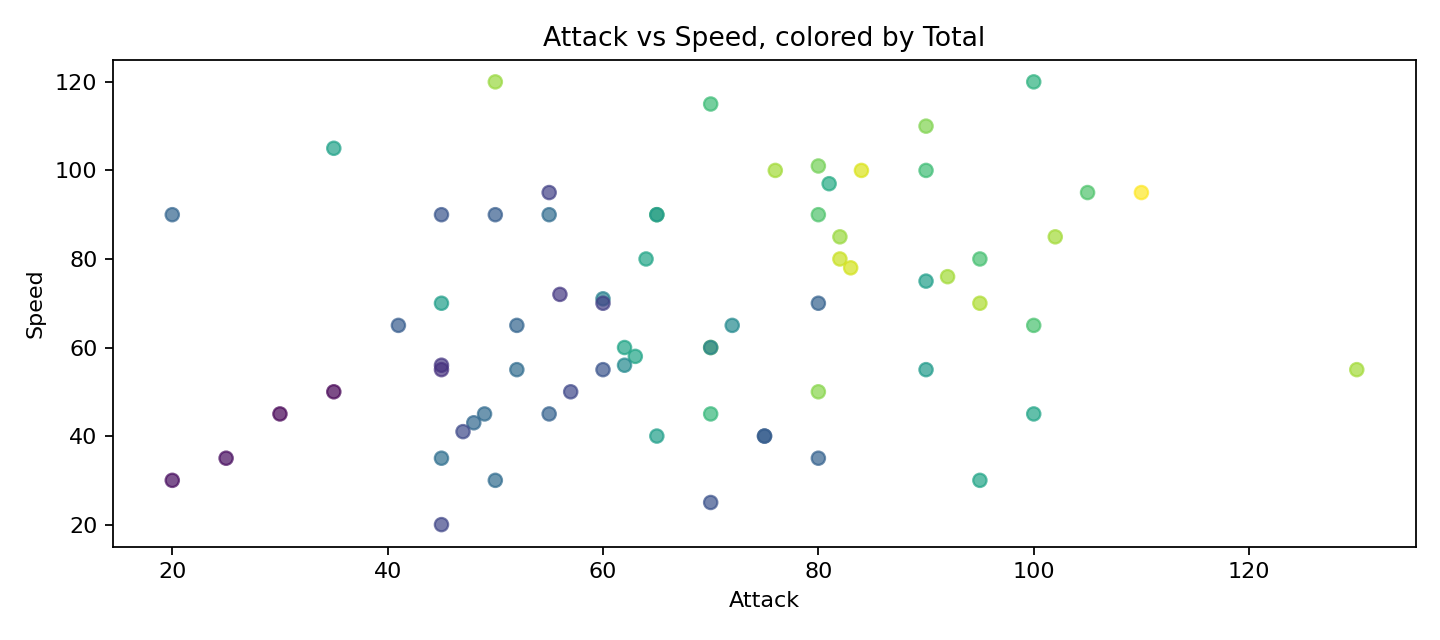

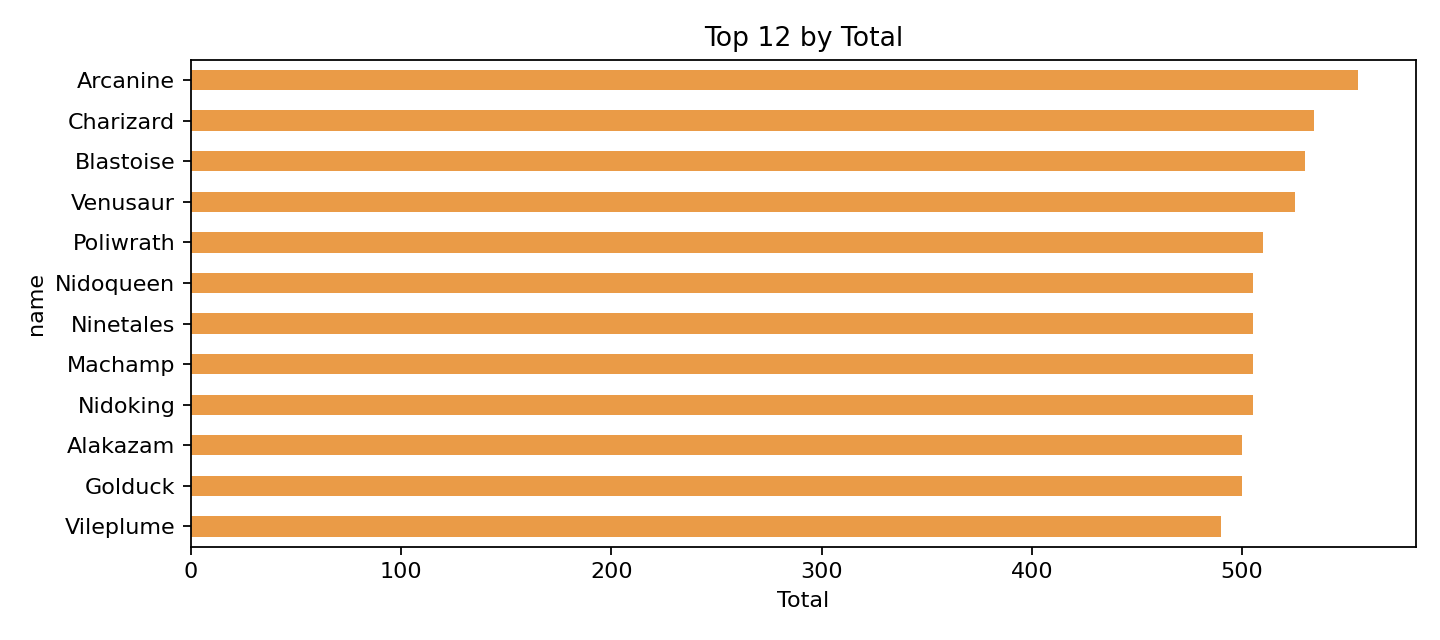

In [9]:
counts=clean.type1.value_counts().sort_values(ascending=True)
avg=clean.groupby('type1')[STATS+['total']].mean().round(1)
avg['n']=clean.groupby('type1').size()
avg=avg.sort_values('total',ascending=False)
avg.to_csv(OUT/'type_summary.csv',encoding='utf-8-sig')

# 포켓몬 수 / 평균 총합 / 타입×6능력치 / 공격-속도 / Top 12
fig,ax=plt.subplots(figsize=(9,4));counts.plot.barh(ax=ax,color='#187A86');ax.set(title='Type distribution',xlabel='Number of Pokémon');fig.tight_layout();fig.savefig(OUT/'01_type_counts.png',dpi=160);plt.close(fig)
fig,ax=plt.subplots(figsize=(9,4));avg.sort_values('total')['total'].plot.barh(ax=ax,color='#755CA6');ax.set(title='Mean base-stat total by primary type',xlabel='Mean Total');fig.tight_layout();fig.savefig(OUT/'02_mean_total.png',dpi=160);plt.close(fig)
fig,ax=plt.subplots(figsize=(9,4));heat=avg[STATS];im=ax.imshow(heat,aspect='auto',cmap='YlGnBu');ax.set(xticks=range(6),xticklabels=STATS,yticks=range(len(heat)),yticklabels=heat.index,title='Mean six base stats by primary type');fig.colorbar(im,ax=ax);fig.tight_layout();fig.savefig(OUT/'03_heatmap.png',dpi=160);plt.close(fig)
fig,ax=plt.subplots(figsize=(9,4));ax.scatter(clean.attack,clean.speed,c=clean.total,cmap='viridis',alpha=.7);ax.set(xlabel='Attack',ylabel='Speed',title='Attack vs Speed, colored by Total');fig.tight_layout();fig.savefig(OUT/'04_attack_speed.png',dpi=160);plt.close(fig)
fig,ax=plt.subplots(figsize=(9,4));clean.nlargest(12,'total').sort_values('total').plot.barh(x='name',y='total',ax=ax,color='#EA9B47',legend=False);ax.set(title='Top 12 by Total',xlabel='Total');fig.tight_layout();fig.savefig(OUT/'05_top12.png',dpi=160);plt.close(fig)
logger.info('EDA FINISH: types=%s, rows=%s',len(avg),len(clean))
print('데이터 모드:',mode,'| 분석 행:',len(clean),'| 1차 타입 종류:',len(avg))
print(avg[['n','total']].head(10))
from IPython.display import display, Image
for name in ['01_type_counts.png','02_mean_total.png','03_heatmap.png','04_attack_speed.png','05_top12.png']:
    display(Image(filename=str(OUT/name),width=720))

## 최종 해석과 제출 시 확인
* 아래 해석은 **실행 시 실제 출력값**을 기준으로 작성해야 합니다. 오프라인 표본 실행에서 결과를 전체 포켓몬의 특성으로 일반화하지 않습니다.
* 주요 혼란 변수: 진화 단계, Mega·지역폼, 표본 범위, 2차 타입, 게임 세대, 종족값과 실전 승률의 차이.
* `output/process_log.txt`를 열어 `LIVE`인지 `OFFLINE_FIXTURE`인지 제출 전 확인합니다.
* **제출 권장**: 이 ipynb + `output/pokemon_raw.csv` + `output/pokemon_clean.csv` + `output/type_summary.csv` + 시각화 PNG + 과정 로그. 수업의 과제별 파일명·브랜치·PR 규칙은 LMS 공지 우선.

In [10]:
from IPython.display import display, Markdown
top=avg.head(3)
print('소스 모드:',mode)
for idx,r in top.iterrows(): print(idx,'평균 총합:',round(r.total,1),'표본수:',int(r.n))
print('저장 결과:', sorted(p.name for p in OUT.iterdir()))
logger.info('END status=%s',mode)

소스 모드: OFFLINE_FIXTURE
Fire 평균 총합: 422.4 표본수: 7
Water 평균 총합: 408.0 표본수: 8
Psychic 평균 총합: 403.3 표본수: 3
저장 결과: ['01_type_counts.png', '02_mean_total.png', '03_heatmap.png', '04_attack_speed.png', '05_top12.png', 'pokemon_clean.csv', 'pokemon_raw.csv', 'process_log.txt', 'type_summary.csv']
